In [1]:
# Isabella Alvarez
# HW 7
# October 7, 2026

In [2]:
import numpy as np              
import matplotlib.pyplot as plt        
from scipy.optimize import curve_fit             

In [3]:
print ("Problem 2) Summaries in PDF")

Problem 2) Summaries in PDF


Problem 3a)


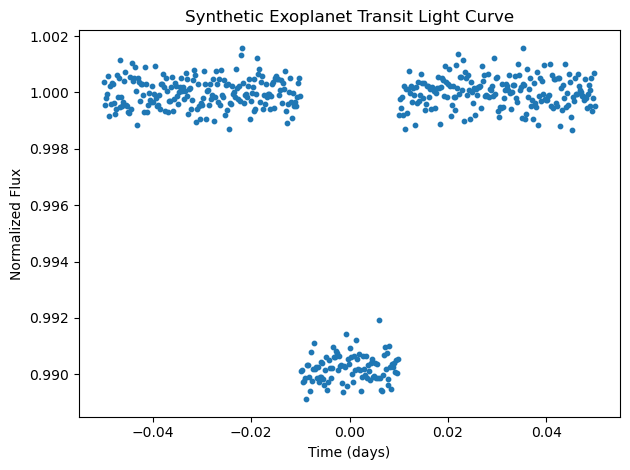

In [4]:
print("Problem 3a)")

# Reading file
data = np.loadtxt("hw7_synthetic_transit_lightcurve.csv", delimiter = ",", skiprows = 1)

# Setting variables
time = data [ : , 0]
flux = data [ : , 1]

# Plot Labeling
plt.xlabel("Time (days)")
plt.ylabel("Normalized Flux")
plt.title("Synthetic Exoplanet Transit Light Curve")

# Plotting
plt.scatter(time, flux, s = 10)
plt.tight_layout()
plt.show()



In [5]:
print("Problem 3b i) Box Window Function")

# Box Window Function
def box_window(x, center, width, height):
    model = np.ones_like(x) # array with normalized flux = 1
    inside = np.abs(x - center) <= (width/2) # Boolean mask
    model [inside] = 1 - height # adjusting model height for "True"
    return model

Problem 3b i) Box Window Function


In [7]:
print("Problem 3b ii) fitting transit data")

# Initial parameter guesses
p0 = [0, 0.01, 0.01] # [center, width, height]

# Curve fit
popt, pcov = curve_fit(box_window, time, flux, p0, method = 'trf', # trf handles rigid steps
                      bounds =([-0.1, 0.001, 0.0], [0.1, 0.5, 1.0])) # min and max bounds 

# Can you believe the fit?
print("You can't always belive the fit. You need to always plot the fitted model over actual observations.")
print("In this case, I needed to constrain parameters to stay within realistic constraints")

Problem 3b ii) fitting transit data
You can't always belive the fit. You need to always plot the fitted model over actual observations.
In this case, I needed to constrain parameters to stay within realistic constraints


In [8]:
print("Problem 3b iii)")

# Obtaining best-fit window function properties
best_center, best_width, best_height = popt

# Best-fit properties print statements
print(f"Best Center: {best_center}")
print(f"Best Width:  {best_width}")
print(f"Best Height: {best_height:.7f}")

# Equation to obtain the Exoplanet radius 
R_star = 1.14

R_planet = (R_star * np.sqrt(best_height))

print(f"Exoplanet radius: {R_planet: .4f}")

Problem 3b iii)
Best Center: 0.0
Best Width:  0.01
Best Height: 0.0097168
Exoplanet radius:  0.1124


Problem 3b iv)


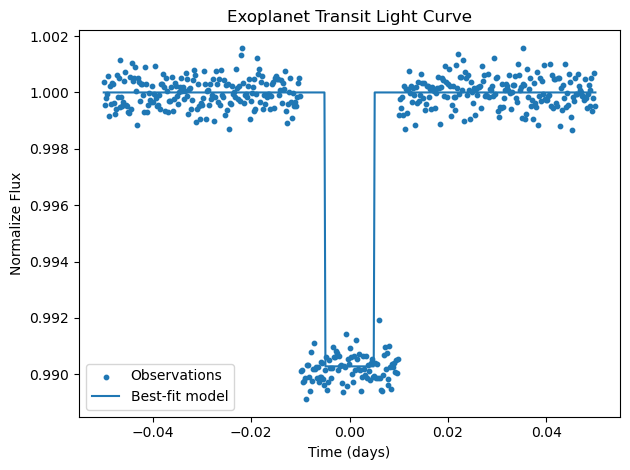

In [9]:
print("Problem 3b iv)")

best_model = box_window(time, best_center, best_width, best_height)

plt.scatter(time, flux, s = 10, label = "Observations")
plt.plot(time, best_model, label = "Best-fit model")

plt.xlabel("Time (days)")
plt.ylabel("Normalize Flux")
plt.title("Exoplanet Transit Light Curve")

plt.legend()
plt.tight_layout()
plt.show()

In [12]:
print("Problem 3c)")

#Measured Value
measured = R_star * np.sqrt (best_height)

#Uncertainties
sigma_star  = 0.01
sigma_depth = 0.002

# Overall Uncertainity
sigma_planet = np.sqrt ( (np.sqrt (best_height) * sigma_star) ** 2 + 
                         (R_star / (2 * np.sqrt(best_height) ) * sigma_depth) **2 )
print(f"Radius uncertainty: {measured:.4f} +- {sigma_planet:.4f}")

Problem 3c)
Radius uncertainty: 0.1124 +- 0.0116
